<a href="https://colab.research.google.com/github/Francisco-Urgiles/Practicas-IA-UPS/blob/main/Practica_03_El_Perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Universidad Politécnica Salesiana
## Inteligencia Artificial — Práctica 03: El Perceptrón

**Carrera:** Ingeniería en Ciencias de la Computación e Inteligencia Artificial  
**Estudiante:** *Francisco Urgiles*  
**Fecha:** Noviembre de 2026

### Introducción
En esta práctica implementamos un perceptrón bipolar desde cero para clasificar puntos bidimensionales. Vamos a visualizar los datos, construir manualmente la regla de aprendizaje, revisar la frontera de decisión y comparar tres tasas de aprendizaje.

**Restricción de librerías:** únicamente se importan `random` (biblioteca estándar) y `matplotlib.pyplot` (exclusivamente para representar gráficos). No se utiliza NumPy, Pandas, SciPy, scikit-learn ni ninguna librería de análisis estadístico o *machine learning*.

**Objetivos:** entender el clasificador lineal, registrar su proceso de aprendizaje y verificar qué tanto generaliza a tres puntos nuevos.

In [1]:
import random
import matplotlib.pyplot as plt

# La semilla permite repetir exactamente las mismas pruebas.
random.seed(13)
print("Configuración correcta: solo random y matplotlib para gráficos.")

Configuración correcta: solo random y matplotlib para gráficos.


---
## Fase 1. Exploración del dataset
### 1.a. Inspección inicial

Escribimos los datos de la guía directamente en listas y contamos manualmente las clases mediante un ciclo.

In [2]:
X = [
    [1, 7], [1, 3], [3, 4], [4, 6], [4, 2], [6, 6], [6, 2],
    [6, 0], [7, 4], [9, 3], [9, 1], [11, 1], [12, 3], [16, 2],
    [4, 8], [6, 8], [8, 9], [9, 7], [10, 11], [12, 9],
    [12, 6], [14, 7], [16, 4]
]
y = [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
      1, 1, 1, 1, 1, 1, 1, 1, 1]

conteo = {-1: 0, 1: 0}
for clase in y:
    conteo[clase] += 1

print("Total de instancias:", len(X))
print("Número de entradas por instancia:", len(X[0]))
print("Clases posibles:", list(conteo.keys()))
print("Clase -1:", conteo[-1], "puntos")
print("Clase +1:", conteo[1], "puntos")
assert len(X) == len(y) == 23
assert conteo[-1] == 14 and conteo[1] == 9

Total de instancias: 23
Número de entradas por instancia: 2
Clases posibles: [-1, 1]
Clase -1: 14 puntos
Clase +1: 9 puntos


**Pregunta guía 1.a.** Cada fila de `X` es una instancia con las coordenadas `x1` y `x2`. En la misma posición de `y` se almacena su etiqueta verdadera. Se trata de clasificación binaria porque hay exactamente dos resultados posibles: `-1` y `+1`. El conjunto contiene **23 instancias, 14 negativas y 9 positivas**.

### 1.b. Representación de las clases

Creamos dos grupos de coordenadas con ciclos y los dibujamos utilizando símbolos distintos. `matplotlib` solo se utiliza para mostrar los resultados.

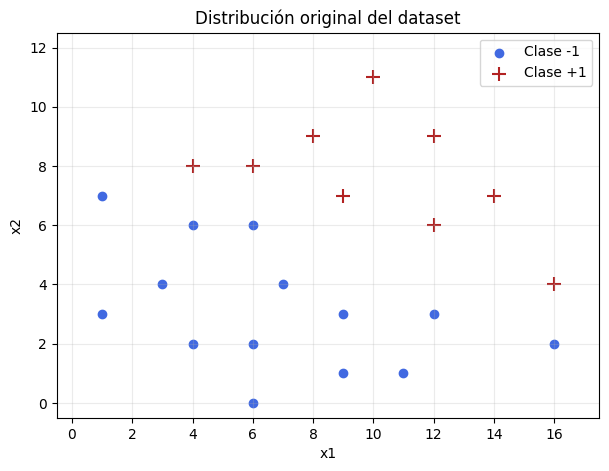

In [3]:
def dibujar_puntos(ax, datos, etiquetas, inicio_nuevos=None):
    negativos_x, negativos_y = [], []
    positivos_x, positivos_y = [], []
    for i in range(len(datos)):
        if etiquetas[i] == -1:
            negativos_x.append(datos[i][0])
            negativos_y.append(datos[i][1])
        else:
            positivos_x.append(datos[i][0])
            positivos_y.append(datos[i][1])

    ax.scatter(negativos_x, negativos_y, marker="o", color="royalblue", label="Clase -1")
    ax.scatter(positivos_x, positivos_y, marker="+", color="firebrick", s=90, label="Clase +1")
    if inicio_nuevos is not None:
        # Marcamos por separado los datos de prueba para identificarlos.
        for i in range(inicio_nuevos, len(datos)):
            ax.scatter(datos[i][0], datos[i][1], marker="s", s=120,
                       facecolors="none", edgecolors="black", linewidths=1.6)
            ax.annotate(str(datos[i]), (datos[i][0]+0.15, datos[i][1]+0.2), fontsize=8)

    ax.set_xlim(-0.5, 17.5)
    ax.set_ylim(-0.5, 12.5)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.grid(True, alpha=0.25)


def plot_dataset(datos, etiquetas, titulo):
    fig, ax = plt.subplots(figsize=(7, 5))
    dibujar_puntos(ax, datos, etiquetas)
    ax.set_title(titulo)
    ax.legend()
    plt.show()

plot_dataset(X, y, "Distribución original del dataset")

**Pregunta guía 1.b.** Sí, visualmente parece que una recta inclinada puede separar los puntos. Los positivos están en general más arriba que los negativos, aunque la coordenada `x1` también influye. La observación visual no demuestra por sí sola la separabilidad; lo comprobaremos entrenando.

---
## Fase 2. Fundamento del perceptrón

Para cada entrada, calculamos la combinación lineal

$$z=w_0+w_1x_1+w_2x_2$$

y aplicamos la activación bipolar: `+1` cuando $z\geq0$, o `-1` cuando $z<0$.

### 2.a. Inicialización de pesos

In [4]:
def initialize_weights():
    pesos = []
    for _ in range(3):
        pesos.append(random.uniform(-0.5, 0.5))
    return pesos

w_initial = initialize_weights()
print("Tres pesos iniciales:", [round(valor, 5) for valor in w_initial])

Tres pesos iniciales: [-0.24099, 0.18526, 0.18408]


**Pregunta guía 2.a.** Se necesitan tres valores porque `w1` y `w2` multiplican a las dos entradas, mientras que `w0` es el **sesgo (bias)**. El sesgo permite desplazar la recta; sin él, la frontera tendría que pasar por el origen.

### 2.b. Activación bipolar

In [5]:
def activation(z):
    if z >= 0:
        return 1
    return -1

print("z=-2:", activation(-2), "| z=0:", activation(0), "| z=3:", activation(3))

z=-2: -1 | z=0: 1 | z=3: 1


**Pregunta guía 2.b.** Las etiquetas `-1` y `+1` corresponden a los dos lados de la frontera `z=0`. Además, si el perceptrón falla, el término `y - predicción` toma el signo necesario para indicar hacia qué clase debe corregirse.

### 2.c. Salida del perceptrón y pruebas manuales

In [6]:
def perceptron_compute(x, w):
    z = w[0] + w[1] * x[0] + w[2] * x[1]
    return activation(z)

for indice in (0, 14, 22):
    punto = X[indice]
    z = w_initial[0] + w_initial[1] * punto[0] + w_initial[2] * punto[1]
    print("Punto:", punto, "| z:", round(z, 4),
          "| real:", y[indice], "| predicho:", perceptron_compute(punto, w_initial))

Punto: [1, 7] | z: 1.2328 | real: -1 | predicho: 1
Punto: [4, 8] | z: 1.9727 | real: 1 | predicho: 1
Punto: [16, 4] | z: 3.4595 | real: 1 | predicho: 1


**Pregunta guía 2.c.** `z` es una suma ponderada continua, por ejemplo `2.3` o `-0.8`; la salida final transforma ese número en una de las dos clases. Solo calcular `z` no ofrece directamente la etiqueta que se compara con `y` para actualizar los pesos.

---
## Fase 3. Visualización de la frontera de decisión

La frontera está formada por los puntos donde $w_0+w_1x_1+w_2x_2=0$. Cuando $w_2\neq0$:

$$x_2=-\frac{w_0+w_1x_1}{w_2}$$

### 3.a. Función `perceptron_plot(X, y, w, title)`

Incluimos el caso vertical para evitar una división entre cero.

In [7]:
def dibujar_frontera(ax, w):
    izquierda, derecha = -0.5, 17.5
    if abs(w[2]) > 1e-12:
        arriba_izquierda = -(w[0] + w[1] * izquierda) / w[2]
        arriba_derecha = -(w[0] + w[1] * derecha) / w[2]
        ax.plot([izquierda, derecha], [arriba_izquierda, arriba_derecha],
                color="forestgreen", linewidth=1.8, label="Frontera z=0")
    elif abs(w[1]) > 1e-12:
        ax.axvline(-w[0] / w[1], color="forestgreen", linewidth=1.8,
                   label="Frontera vertical")
    else:
        # w1=w2=0: z es constante y no define una recta útil.
        ax.text(0.5, 0.95, "No existe frontera lineal", ha="center",
                va="top", transform=ax.transAxes)


def perceptron_plot(X, y, w, title):
    fig, ax = plt.subplots(figsize=(7, 5))
    dibujar_puntos(ax, X, y)
    dibujar_frontera(ax, w)
    ax.set_title(title)
    ax.legend(loc="upper right")
    plt.show()

print("Función de graficación definida.")

Función de graficación definida.


**Pregunta guía 3.a.** Geométricamente, la recta es el límite entre las regiones predichas como `-1` y `+1`. Los pesos aleatorios pueden ubicarla en cualquier lugar, incluso atravesando ambas clases; todavía no contienen información aprendida del dataset.

### 3.b. Frontera con pesos iniciales

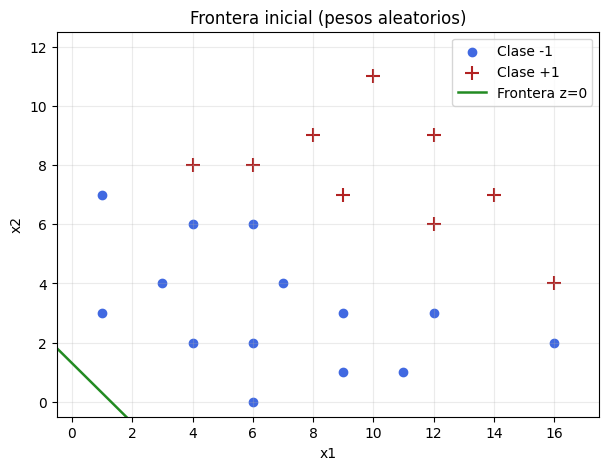

Aciertos antes del aprendizaje: 9 de 23
Errores antes del aprendizaje: 14


In [8]:
perceptron_plot(X, y, w_initial, "Frontera inicial (pesos aleatorios)")
aciertos_antes = 0
for i in range(len(X)):
    if perceptron_compute(X[i], w_initial) == y[i]:
        aciertos_antes += 1
print("Aciertos antes del aprendizaje:", aciertos_antes, "de", len(X))
print("Errores antes del aprendizaje:", len(X) - aciertos_antes)

**Pregunta guía 3.b.** La frontera inicial **no clasifica correctamente todas las instancias**: con la semilla usada, acierta **9 de 23**. No es razonable esperar que una elección aleatoria encuentre la recta correcta sin observar las etiquetas.

---
## Fase 4. Entrenamiento manual del perceptrón

Si la predicción es incorrecta, usamos la regla de la guía:

$$w_i\leftarrow w_i+\eta(y-\hat y)x_i, \qquad w_0\leftarrow w_0+\eta(y-\hat y)$$

La **época** es una pasada completa por los 23 puntos; `lr` representa $\eta$.

### 4.a. Función de aprendizaje

Retornamos los pesos finales, la cantidad de épocas, el total de actualizaciones y los historiales `W_values` y `E_values`.

In [9]:
def perceptron_learning(X, y, w, lr, max_epochs):
    pesos_actuales = w[:]   # nunca alteramos la lista inicial recibida
    W_values, E_values = [], []
    total_actualizaciones = 0

    for epoca in range(1, max_epochs + 1):
        fallos = 0
        for i in range(len(X)):
            predicho = perceptron_compute(X[i], pesos_actuales)
            if predicho != y[i]:
                fallos += 1
                diferencia = lr * (y[i] - predicho)
                pesos_actuales[0] += diferencia
                pesos_actuales[1] += diferencia * X[i][0]
                pesos_actuales[2] += diferencia * X[i][1]
                total_actualizaciones += 1

        E_values.append(fallos / len(X))
        W_values.append(pesos_actuales[:])   # copia independiente en cada época
        if fallos == 0:
            break

    return pesos_actuales, epoca, total_actualizaciones, W_values, E_values

print("Regla de entrenamiento implementada con ciclos y operaciones básicas.")

Regla de entrenamiento implementada con ciclos y operaciones básicas.


**Pregunta guía 4.a.** `max_epochs` evita entrenar indefinidamente. Si las clases no fueran separables con una recta, el algoritmo podría seguir alternando correcciones sin alcanzar cero errores.

### 4.b. Registro de error

La tasa de error en cada pasada se calcula como `fallos / len(X)` y se agrega a `E_values`. El conteo corresponde a las predicciones hechas **durante** esa pasada, antes de cada posible corrección.

**Pregunta guía 4.b.** Un valor cero indica que hubo una época completa sin clasificaciones incorrectas, de modo que los pesos ya separan todos los puntos usados para entrenar.

### 4.c. Historial de pesos

Al final de cada época se guardan **copias** de los tres pesos, no referencias a la misma lista.

**Pregunta guía 4.c.** Si se guardara repetidamente el mismo objeto `pesos_actuales`, las modificaciones posteriores sobrescribirían el historial: las gráficas mostrarían el estado final en lugar de la evolución real.

---
## Fase 5. Entrenamiento con `lr = 0.5`
### 5.a. Experimento principal

Aplicamos 1000 épocas como límite y comenzamos desde una copia de los pesos iniciales.

In [10]:
final_w, epochs, updates, W_values, E_values = perceptron_learning(
    X, y, w_initial, lr=0.5, max_epochs=1000
)

print("Pesos iniciales:", [round(v, 4) for v in w_initial])
print("Pesos finales:", [round(v, 4) for v in final_w])
print("Épocas ejecutadas:", epochs)
print("Actualizaciones:", updates)
print("Última tasa de error:", E_values[-1])

correctos = 0
for punto, clase in zip(X, y):
    if perceptron_compute(punto, final_w) == clase:
        correctos += 1
print("Clasificaciones correctas al terminar:", correctos, "/", len(X))

Pesos iniciales: [-0.241, 0.1853, 0.1841]
Pesos finales: [-29.241, 1.1853, 3.1841]
Épocas ejecutadas: 54
Actualizaciones: 143
Última tasa de error: 0.0
Clasificaciones correctas al terminar: 23 / 23


**Pregunta guía 5.a.** Sí, hubo convergencia: con la semilla `13` y `lr=0.5` el entrenamiento terminó en **54 épocas**, con **143 actualizaciones**, y `E_values[-1] = 0.0`. Ese valor indica una época sin errores; lo confirmamos comprobando las 23 predicciones finales.

### 5.b. Gráfica de la frontera final

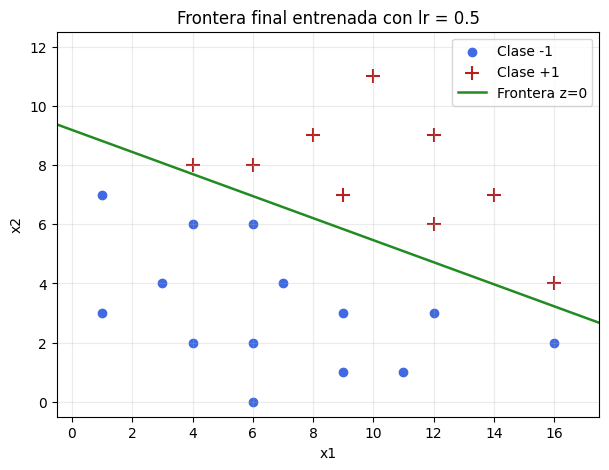

In [11]:
perceptron_plot(X, y, final_w, "Frontera final entrenada con lr = 0.5")

**Pregunta guía 5.b.** Sí. La frontera final deja las dos clases en regiones opuestas. A diferencia de la recta aleatoria de la fase 3, la recta aprendida ya separa los 23 ejemplos: cambió tanto su posición como su inclinación.

---
## Fase 6. Clasificación de nuevas instancias
### 6.a. Predicciones fuera del entrenamiento

Evaluamos uno a uno los tres ejemplos pedidos por la guía. `perceptron_compute` recibe **una** instancia por llamada.

In [12]:
X_test = [[5, 5], [10, 6], [6, 10]]
y_pred = []

print("Instancia      | Clase predicha | Suma z")
print("-" * 44)
for punto in X_test:
    clase_predicha = perceptron_compute(punto, final_w)
    valor_z = final_w[0] + final_w[1] * punto[0] + final_w[2] * punto[1]
    y_pred.append(clase_predicha)
    print(f"{str(punto):14} | {clase_predicha:^14} | {valor_z: .4f}")

Instancia      | Clase predicha | Suma z
--------------------------------------------
[5, 5]         |       -1       | -7.3943
[10, 6]        |       1        |  1.7161
[6, 10]        |       1        |  9.7114


**Pregunta guía 6.a.** Las predicciones son coherentes con las regiones del plano: `[5, 5]` cae del lado `-1`, mientras que `[10, 6]` y `[6, 10]` caen del lado `+1`. El signo de `z` muestra matemáticamente en qué lado queda cada punto.

### 6.b. Ampliación del dataset

Creamos una copia de los datos antes de incorporar puntos nuevos, para no modificar el entrenamiento original. Sus etiquetas añadidas son las **predicciones** del modelo, no etiquetas verdaderas comprobadas.

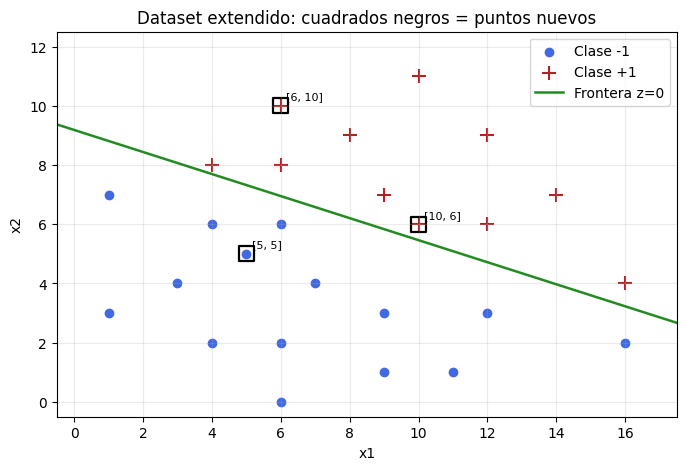

Tamaño del dataset extendido: 26


In [13]:
X_extended = [fila[:] for fila in X]
y_extended = y[:]

for i in range(len(X_test)):
    X_extended.append(X_test[i][:])
    y_extended.append(y_pred[i])

fig, ax = plt.subplots(figsize=(8, 5))
dibujar_puntos(ax, X_extended, y_extended, inicio_nuevos=len(X))
dibujar_frontera(ax, final_w)
ax.set_title("Dataset extendido: cuadrados negros = puntos nuevos")
ax.legend(loc="upper right")
plt.show()
print("Tamaño del dataset extendido:", len(X_extended))

**Pregunta guía 6.b.** Los tres puntos nuevos están en la región que predijo el modelo. El caso `[10, 6]` es el más cercano a la frontera **en este entrenamiento** (tiene el menor valor absoluto de `z` entre los puntos positivos probados), por lo que su predicción es más sensible a un desplazamiento de la recta. Su clase se debe interpretar como predicción, no como verdad conocida.

---
## Fase 7. Evolución de la frontera
### 7.a. Seis momentos del aprendizaje

Usamos el estado inicial, los momentos aproximados del 20 %, 40 %, 60 % y 80 %, y el estado final. Cuando hay muy pocas épocas, se muestran solamente los estados distintos disponibles.

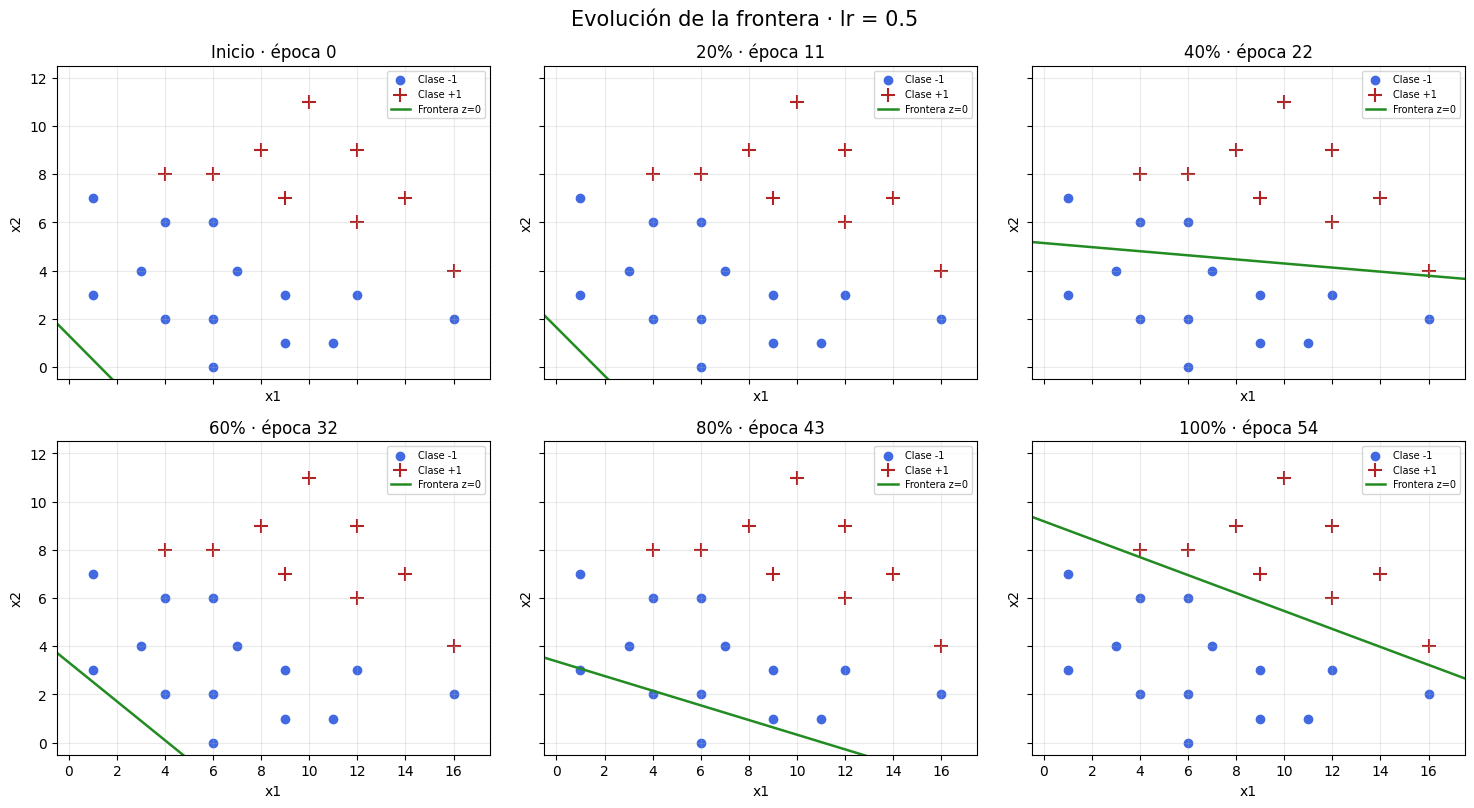

In [14]:
def plot_evolution(X, y, inicial, historial, titulo):
    cantidad = len(historial)
    estados = [("Inicio", 0)]
    if cantidad < 5:
        for e in range(1, cantidad + 1):
            estados.append((f"Época {e}", e))
    else:
        for porcentaje in (20, 40, 60, 80, 100):
            ep = max(1, round(cantidad * porcentaje / 100))
            estados.append((f"{porcentaje}%", ep))

    # Evitamos repetir una época debido al redondeo.
    unicos, vistos = [], set()
    for nombre, e in estados:
        if e not in vistos:
            vistos.add(e)
            unicos.append((nombre, e))

    fig, ejes = plt.subplots(2, 3, figsize=(15, 8.2), sharex=True, sharey=True)
    lista_ejes = [ejes[0][0], ejes[0][1], ejes[0][2],
                  ejes[1][0], ejes[1][1], ejes[1][2]]
    for i, (nombre, e) in enumerate(unicos):
        ax = lista_ejes[i]
        pesos = inicial if e == 0 else historial[e - 1]
        dibujar_puntos(ax, X, y)
        dibujar_frontera(ax, pesos)
        ax.set_title(f"{nombre} · época {e}")
        ax.legend(fontsize=7, loc="upper right")
    for i in range(len(unicos), 6):
        lista_ejes[i].axis("off")
    fig.suptitle(titulo, fontsize=15)
    fig.tight_layout()
    plt.show()

plot_evolution(X, y, w_initial, W_values, "Evolución de la frontera · lr = 0.5")

**Pregunta guía 7.a.** La recta se desplaza y rota a medida que se corrigen clasificaciones. El cambio no tiene por qué ser suave: los pesos pueden recibir varias actualizaciones dentro de una época y un pequeño cambio en ellos puede alterar visiblemente la recta.

### 7.b. Interpretación de la pendiente y del sesgo

In [15]:
if abs(final_w[2]) > 1e-12:
    pendiente = -final_w[1] / final_w[2]
    corte = -final_w[0] / final_w[2]
    print("Pendiente final:", round(pendiente, 4))
    print("Intersección con el eje x2:", round(corte, 4))
else:
    print("La frontera es vertical, por lo que su pendiente no es finita.")

Pendiente final: -0.3722
Intersección con el eje x2: 9.1835


**Pregunta guía 7.b.** No existe un único peso responsable de la inclinación: cuando `w2` no es cero, la pendiente es $-w_1/w_2$, es decir, depende de la relación entre ambos. El sesgo `w0` controla el desplazamiento de la recta sin cambiar la pendiente si `w1` y `w2` permanecen constantes.

---
## Fase 8. Evolución del error
### 8.a. Gráfica de error por época

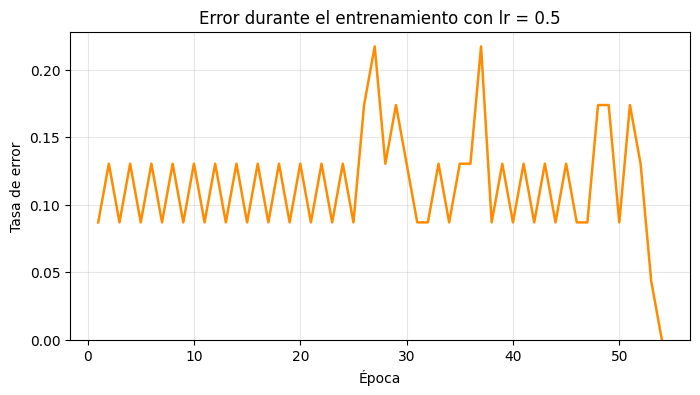

In [16]:
def plot_error(E_values, title):
    epocas = []
    for i in range(len(E_values)):
        epocas.append(i + 1)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(epocas, E_values, color="darkorange", linewidth=1.8)
    ax.set_title(title)
    ax.set_xlabel("Época")
    ax.set_ylabel("Tasa de error")
    ax.set_ylim(bottom=0)
    ax.grid(True, alpha=0.3)
    plt.show()

plot_error(E_values, "Error durante el entrenamiento con lr = 0.5")

**Pregunta guía 8.a.** El error no disminuye estrictamente en cada época. Una corrección puede mejorar algunos puntos y empeorar momentáneamente otros, de manera que la cantidad de errores puede subir, bajar o mantenerse antes de alcanzar cero.

### 8.b. Interpretación de la convergencia

In [17]:
print("Tasa de error inicial del entrenamiento:", round(E_values[0], 4))
print("Tasa de error final:", round(E_values[-1], 4))
print("¿Convergió?:", "Sí" if E_values[-1] == 0 else "No en el límite indicado")

Tasa de error inicial del entrenamiento: 0.087
Tasa de error final: 0.0
¿Convergió?: Sí


**Pregunta guía 8.b.** Un error final igual a cero significa que en la última época no hubo fallos **en los 23 datos de entrenamiento**. No implica perfección en datos futuros: el perceptrón solo puede representar una frontera lineal y no conoce etiquetas reales de ejemplos nuevos.

---
## Fase 9. Comparación de tasas de aprendizaje
### 9.a. Tres entrenamientos con idéntica inicialización

Para comparar `lr=0.3`, `lr=0.5` y `lr=0.8`, usamos los **mismos** pesos iniciales y el mismo orden de datos. Así aislamos el efecto de la tasa de aprendizaje en estos experimentos.

In [18]:
tasas = [0.3, 0.5, 0.8]
resultados = {}
for tasa in tasas:
    pesos, epocas, cambios, historia_pesos, historia_error = perceptron_learning(
        X, y, w_initial[:], lr=tasa, max_epochs=1000
    )
    resultados[tasa] = {
        "pesos": pesos,
        "epocas": epocas,
        "actualizaciones": cambios,
        "W_values": historia_pesos,
        "E_values": historia_error
    }
    print(f"lr={tasa}: épocas={epocas}, cambios={cambios}, último error={historia_error[-1]:.4f}")

lr=0.3: épocas=123, cambios=400, último error=0.0000
lr=0.5: épocas=54, cambios=143, último error=0.0000
lr=0.8: épocas=83, cambios=249, último error=0.0000


**Pregunta guía 9.a.** No sería una comparación justa comenzar con pesos distintos: una diferencia en el número de épocas podría deberse a la posición de partida de la recta y no a la tasa `lr`. Usar la misma inicialización y el mismo orden hace la comparación más controlada.

### 9.b. Fronteras y errores para las tres tasas

Para cada tasa se muestran seis instantes del entrenamiento y la curva de error.

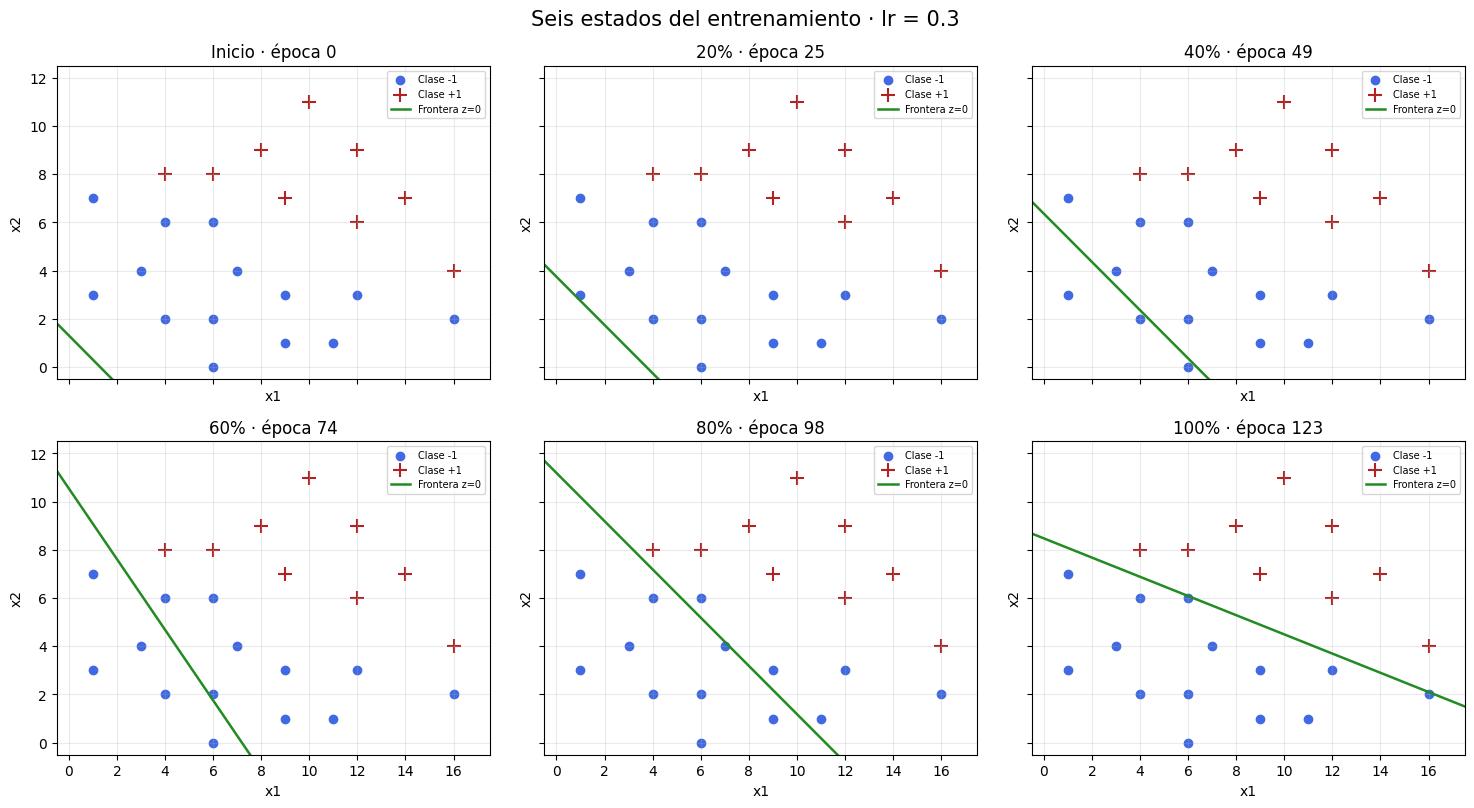

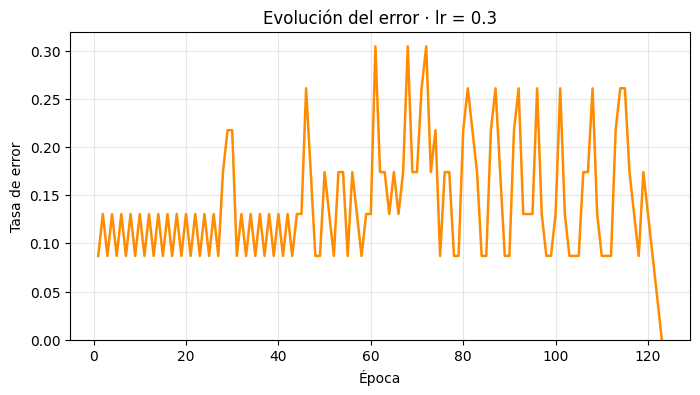

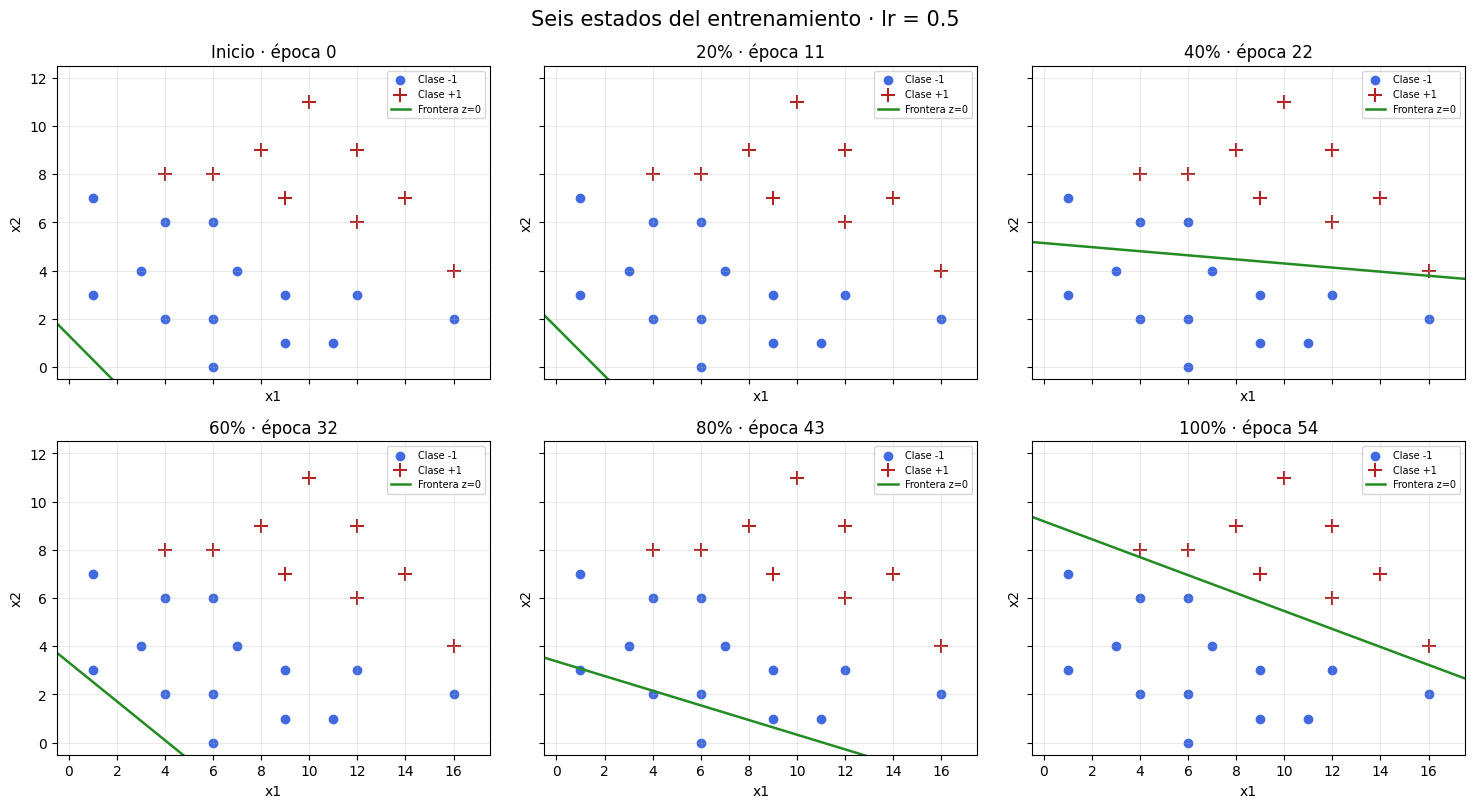

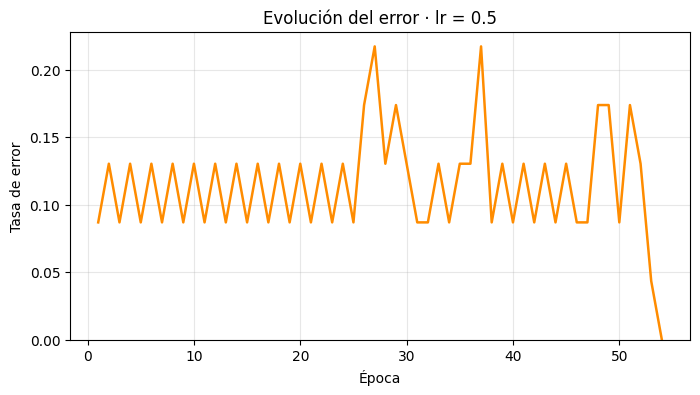

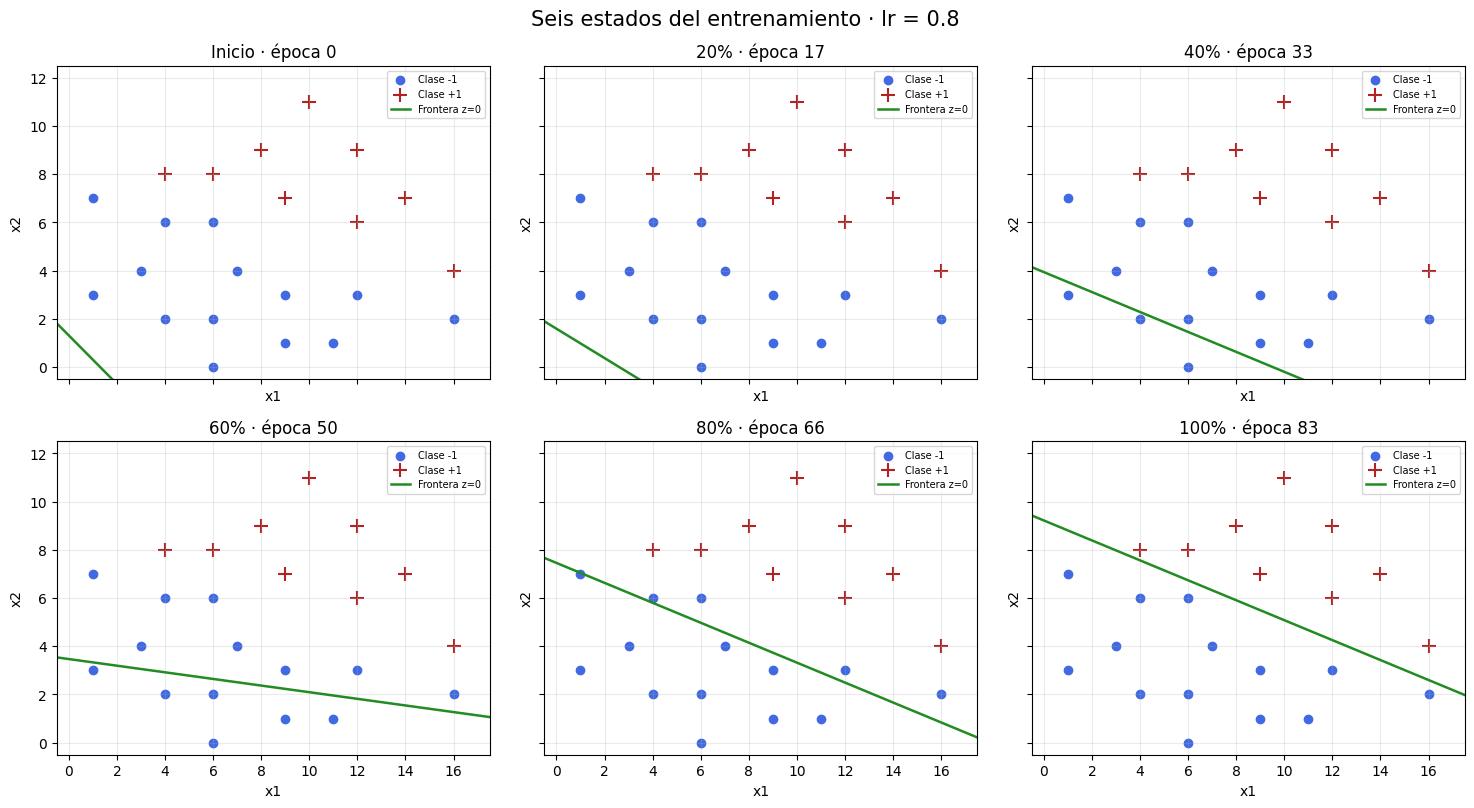

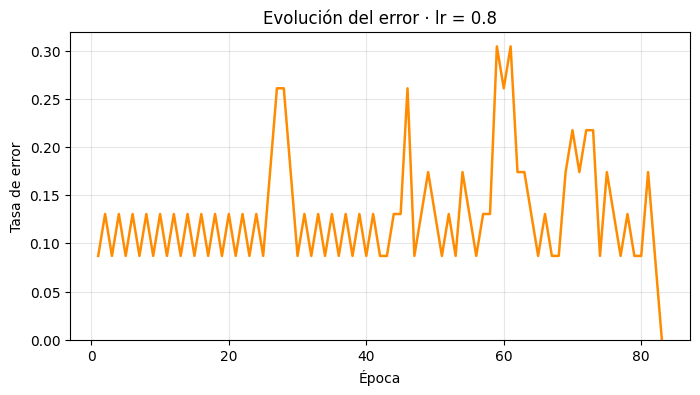

In [19]:
for tasa in tasas:
    experimento = resultados[tasa]
    plot_evolution(X, y, w_initial, experimento["W_values"],
                   f"Seis estados del entrenamiento · lr = {tasa}")
    plot_error(experimento["E_values"], f"Evolución del error · lr = {tasa}")

**Pregunta guía 9.b.** En esta ejecución reproducible (semilla `13`), **`lr=0.5`** convergió con menos épocas (**54**), seguido de `lr=0.8` (**83**) y `lr=0.3` (**123**). Esto **no** prueba que 0.5 sea universalmente superior: cambiar el orden, los datos o los pesos iniciales puede producir otra comparación.

### 9.c. Tabla comparativa de resultados

In [20]:
print(f"{'lr':<6} {'Épocas':<9} {'Actualizaciones':<18} {'Error final':<13} Pesos finales")
print("-" * 100)
for tasa in tasas:
    r = resultados[tasa]
    pesos_redondeados = [round(v, 4) for v in r["pesos"]]
    print(f"{tasa:<6} {r['epocas']:<9} {r['actualizaciones']:<18} "
          f"{r['E_values'][-1]:<13.4f} {pesos_redondeados}")

lr     Épocas    Actualizaciones    Error final   Pesos finales
----------------------------------------------------------------------------------------------------
0.3    123       400                0.0000        [-42.241, 1.9853, 4.9841]
0.5    54        143                0.0000        [-29.241, 1.1853, 3.1841]
0.8    83        249                0.0000        [-75.441, 3.3853, 8.1841]


**Pregunta guía 9.c.** Los pesos finales no son iguales entre tasas: cada `lr` genera correcciones de tamaño diferente y por eso puede terminar en otra recta. El dataset admite **más de una** frontera lineal válida, así que distintas combinaciones de pesos pueden clasificar correctamente los 23 puntos.

---
## Resultados obtenidos

1. Se usaron **23 datos** con dos entradas y etiquetas bipolares: 14 ejemplos de clase `-1` y 9 de clase `+1`.
2. Se implementaron desde cero el cálculo de `z`, la activación bipolar y la actualización de los pesos (incluido el sesgo).
3. Con la semilla fija de este notebook, el entrenamiento principal (`lr=0.5`) alcanzó **0 errores** después de **54 épocas** y **143 actualizaciones**.
4. El modelo predijo `[5, 5] → -1`, `[10, 6] → +1` y `[6, 10] → +1`.
5. Los tres entrenamientos comparativos terminaron con error cero, aunque usaron diferentes cantidades de épocas y terminaron con pesos distintos.

## Conclusiones

- **Conclusión a partir de los resultados:** el perceptrón aprende modificando una frontera lineal cuando sus predicciones no coinciden con las etiquetas reales; no es necesario usar herramientas de aprendizaje automático para implementar la regla de actualización.
- **Observación del experimento:** una tasa de aprendizaje mayor no siempre produce convergencia más rápida. En estos datos, `0.5` tardó menos que `0.3` y `0.8`. La tasa conveniente depende de las condiciones del entrenamiento.
- **Conclusión personal (revisa y redacta en tus propias palabras antes de entregar):** lo que más me llamó la atención fue que la gráfica de error no disminuyó perfectamente en cada época, a pesar de que la frontera terminó separando correctamente los datos. Esto muestra que el aprendizaje ocurre mediante correcciones sucesivas y no necesariamente como una mejora uniforme.

## Referencias

- Rosenblatt, F. (1958). *The Perceptron: A Probabilistic Model for Information Storage and Organization in the Brain*. Psychological Review, 65(6), 386–408.
- McCulloch, W. S., & Pitts, W. (1943). *A Logical Calculus of the Ideas Immanent in Nervous Activity*. Bulletin of Mathematical Biophysics, 5, 115–133.


---
## Verificación final

Revisamos que los datos no se hayan modificado accidentalmente, que cada historial tenga una entrada por época, que la función devuelva únicamente `-1` o `+1`, y que los experimentos hayan concluido correctamente.

In [21]:
assert len(X) == len(y) == 23
assert len(X_extended) == len(y_extended) == 26
assert len(X_test) == len(y_pred) == 3
assert len(W_values) == len(E_values) == epochs
assert all(pred in (-1, 1) for pred in y_pred)
assert E_values[-1] == 0
assert all(resultados[t]["E_values"][-1] == 0 for t in tasas)
assert all(len(resultados[t]["W_values"]) == resultados[t]["epocas"] for t in tasas)
assert w_initial == [
    -0.24099150828452642, 0.18525799296453693, 0.18408191801611073
]
print("Todas las verificaciones se completaron correctamente.")

Todas las verificaciones se completaron correctamente.
